In [1]:
# --- Install core libraries ---
!pip install opencv-python-headless matplotlib numpy scikit-image scipy

# --- Install FLIR radiometric extractor ---
!pip install flirimageextractor


   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 2.6/2.6 MB 19.8 MB/s eta 0:00:00
   ---------------------------------------- 0.0/3.4 MB ? eta -:--:--
   ---------------------------------------- 3.4/3.4 MB 53.2 MB/s eta 0:00:00

  Attempting uninstall: pillow

    Found existing installation: pillow 11.1.0

    Uninstalling pillow-11.1.0:

      Successfully uninstalled pillow-11.1.0

   ------ --------------------------------- 1/6 [pillow]
   ------ --------------------------------- 1/6 [pillow]
   ------ --------------------------------- 1/6 [pillow]
   ------ --------------------------------- 1/6 [pillow]
   ------ --------------------------------- 1/6 [pillow]
   ------ --------------------------------- 1/6 [pillow]
   ------ --------------------------------- 1/6 [pillow]
   ------ --------------------------------- 1/6 [pillow]
   ------ --------------------------------- 1/6 [pillow]
   ------ -------------------------

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.45.1 requires packaging<25,>=20, but you have packaging 25.0 which is incompatible.


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, morphology
from scipy import ndimage

# For radiometric FLIR extraction
from flirimageextractor import FlirImageExtractor

# For nicer plots
plt.style.use("seaborn-v0_8-darkgrid")


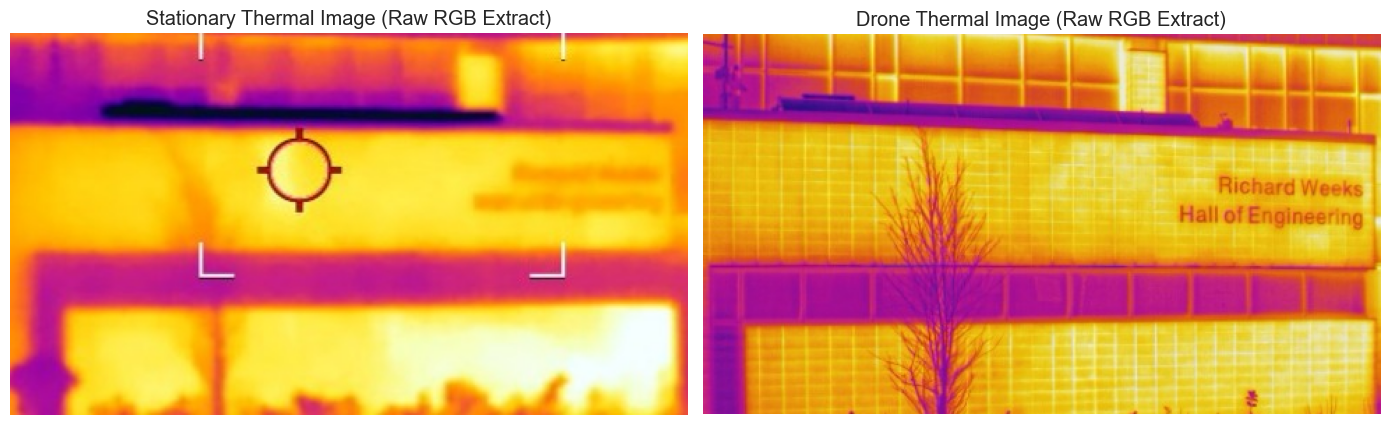

In [3]:
# --- File paths ---
stationary_path = r"C:\Users\murat\Downloads\THERMAL CROPPED IRX.JPG"
drone_path      = r"C:\Users\murat\Downloads\DRONE CROPPED IRX_3353.JPG"

# --- Load images with cv2 (OpenCV loads in BGR) ---
img_stationary_bgr = cv2.imread(stationary_path)
img_drone_bgr      = cv2.imread(drone_path)

# Convert to RGB for correct display
img_stationary = cv2.cvtColor(img_stationary_bgr, cv2.COLOR_BGR2RGB)
img_drone      = cv2.cvtColor(img_drone_bgr, cv2.COLOR_BGR2RGB)

# --- Display side by side ---
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(img_stationary)
ax[0].set_title("Stationary Thermal Image (Raw RGB Extract)")
ax[0].axis("off")

ax[1].imshow(img_drone)
ax[1].set_title("Drone Thermal Image (Raw RGB Extract)")
ax[1].axis("off")

plt.tight_layout()
plt.show()


In [5]:
# --- Extract radiometric temperature data ---
flir = FlirImageExtractor()       # No arguments allowed in recent versions
flir.process_image(stationary_path)

# Extract raw temperature array
stationary_temp = flir.get_thermal_np()

print("Stationary image temperature array shape:", stationary_temp.shape)
print("Example temperature values:", stationary_temp[0:5, 0:5])


File paths successfully generated:
DIRP: C:\Users\murat\anaconda3\Lib\site-packages\dji_executables\dji_thermal_sdk_v1.7\windows/release_x64/libdirp.dll
DIRP Sub: C:\Users\murat\anaconda3\Lib\site-packages\dji_executables\dji_thermal_sdk_v1.7\windows/release_x64/libv_dirp.dll
IIRP: C:\Users\murat\anaconda3\Lib\site-packages\dji_executables\dji_thermal_sdk_v1.7\windows/release_x64/libv_iirp.dll
ExifTool: C:\Users\murat\anaconda3\Lib\site-packages\dji_executables\dji_thermal_sdk_v1.7\exiftool-12.35.exe


UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x000002311BF97920>

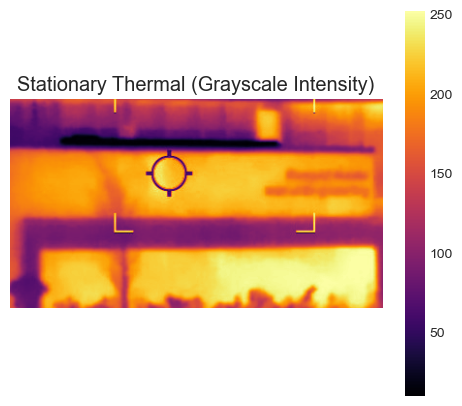

In [6]:
# Convert stationary RGB to grayscale (thermal-like intensity)
stationary_gray = cv2.cvtColor(img_stationary, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(6, 5))
plt.imshow(stationary_gray, cmap='inferno')
plt.title("Stationary Thermal (Grayscale Intensity)")
plt.axis("off")
plt.colorbar()
plt.show()


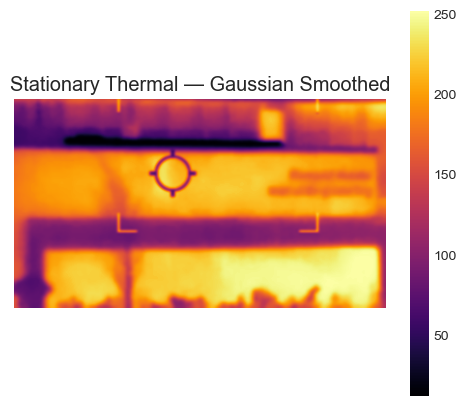

In [7]:
# Gentle Gaussian smoothing
stationary_gauss = cv2.GaussianBlur(stationary_gray, (7, 7), sigmaX=1.2)

plt.figure(figsize=(6, 5))
plt.imshow(stationary_gauss, cmap='inferno')
plt.title("Stationary Thermal — Gaussian Smoothed")
plt.axis("off")
plt.colorbar()
plt.show()


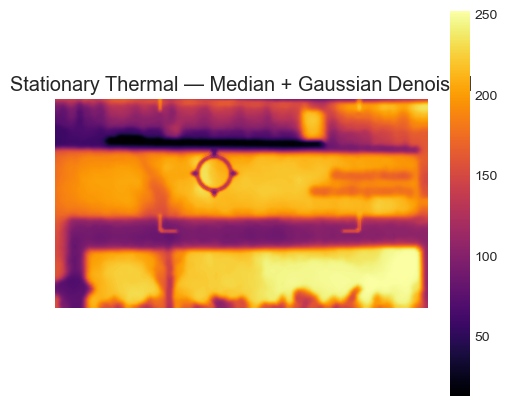

In [8]:
# Median filter to suppress isolated noise
stationary_median = cv2.medianBlur(stationary_gauss, 5)

plt.figure(figsize=(6, 5))
plt.imshow(stationary_median, cmap='inferno')
plt.title("Stationary Thermal — Median + Gaussian Denoised")
plt.axis("off")
plt.colorbar()
plt.show()


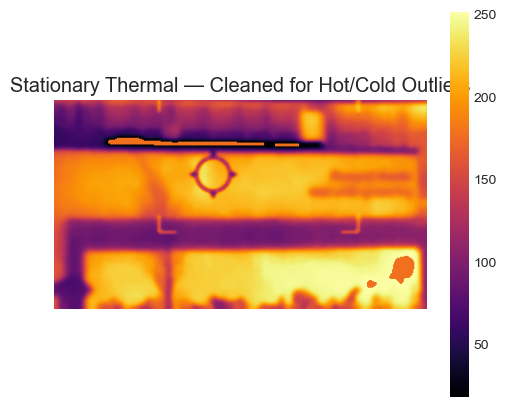

In [9]:
# Remove small bright/hot pixels
clean_hot = morphology.remove_small_objects(stationary_median > np.percentile(stationary_median, 99), 30)

# Remove small dark/cold pixels
clean_cold = morphology.remove_small_objects(stationary_median < np.percentile(stationary_median, 1), 30)

# Combine mask to clean only those spots
stationary_clean = stationary_median.copy()
stationary_clean[clean_hot] = np.median(stationary_median)
stationary_clean[clean_cold] = np.median(stationary_median)

plt.figure(figsize=(6, 5))
plt.imshow(stationary_clean, cmap='inferno')
plt.title("Stationary Thermal — Cleaned for Hot/Cold Outliers")
plt.axis("off")
plt.colorbar()
plt.show()


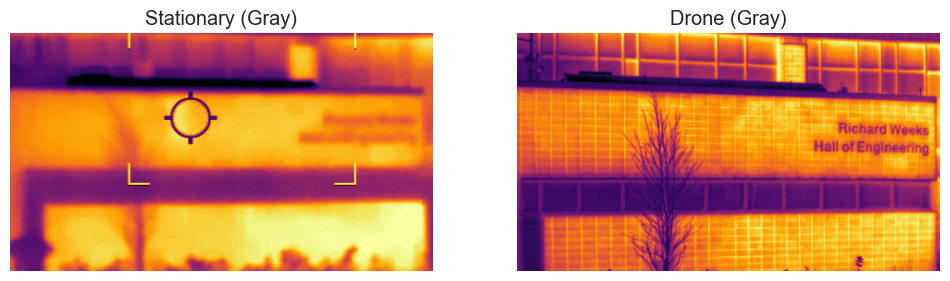

In [14]:
# Convert both to grayscale
stationary_gray = cv2.cvtColor(img_stationary, cv2.COLOR_RGB2GRAY)
drone_gray = cv2.cvtColor(img_drone, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(stationary_gray, cmap="inferno")
plt.title("Stationary (Gray)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(drone_gray, cmap="inferno")
plt.title("Drone (Gray)")
plt.axis("off")

plt.show()


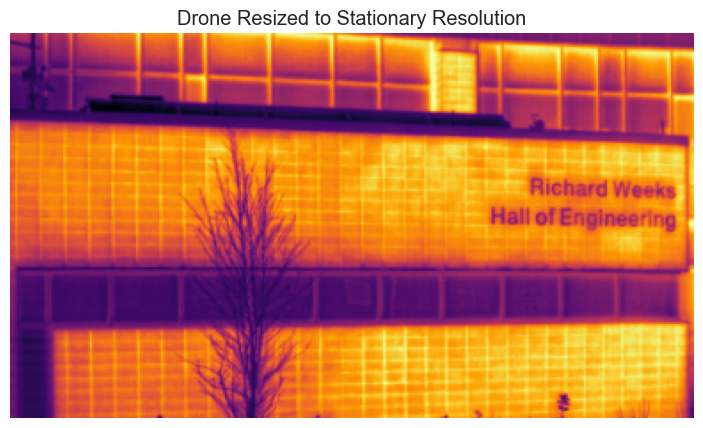

In [15]:
# Make drone image the same size as stationary
drone_resized = cv2.resize(drone_gray, (stationary_gray.shape[1], stationary_gray.shape[0]))

plt.figure(figsize=(12,5))
plt.imshow(drone_resized, cmap="inferno")
plt.title("Drone Resized to Stationary Resolution")
plt.axis("off")
plt.show()


In [16]:
stationary_clean = cv2.GaussianBlur(stationary_gray, (5,5), 1)
drone_clean = cv2.GaussianBlur(drone_resized, (5,5), 1)


In [17]:
# Flatten both images
x_stationary = stationary_clean.flatten().astype(float)
y_drone = drone_clean.flatten().astype(float)

# Subsample to avoid 300k+ points
np.random.seed(42)
idx = np.random.choice(len(x_stationary), size=25000, replace=False)

x_sample = x_stationary[idx]
y_sample = y_drone[idx]

print("Sample size:", len(x_sample))


Sample size: 25000


In [10]:
# Flatten both images
x_vals = stationary_gray.flatten().astype(float)
y_vals = stationary_clean.flatten().astype(float)

print("Raw paired size:", len(x_vals))

# Optional subsampling (helps performance, keeps randomness)
np.random.seed(42)
idx = np.random.choice(len(x_vals), size=20000, replace=False)

x_sample = x_vals[idx]
y_sample = y_vals[idx]

print("Sample size used for regression:", len(x_sample))


Raw paired size: 83545
Sample size used for regression: 20000


In [18]:
# Fit polynomial models (1, 2, 3 degree)
coef1 = np.polyfit(x_sample, y_sample, 1)
coef2 = np.polyfit(x_sample, y_sample, 2)
coef3 = np.polyfit(x_sample, y_sample, 3)

p1 = np.poly1d(coef1)
p2 = np.poly1d(coef2)
p3 = np.poly1d(coef3)

coef1, coef2, coef3


(array([ 0.55752903, 59.95477749]),
 array([-9.42118139e-04,  8.41567517e-01,  4.18130157e+01]),
 array([-1.04845947e-06, -4.97973082e-04,  7.86333591e-01,  4.36908215e+01]))

In [11]:
# Fit polynomial models
coef_deg1 = np.polyfit(x_sample, y_sample, 1)
coef_deg2 = np.polyfit(x_sample, y_sample, 2)
coef_deg3 = np.polyfit(x_sample, y_sample, 3)

p1 = np.poly1d(coef_deg1)
p2 = np.poly1d(coef_deg2)
p3 = np.poly1d(coef_deg3)

coef_deg1, coef_deg2, coef_deg3


(array([ 0.89879229, 17.69815893]),
 array([1.72093446e-03, 3.81715865e-01, 5.03924699e+01]),
 array([-3.07475496e-05,  1.46773308e-02, -1.21412319e+00,  1.03630986e+02]))

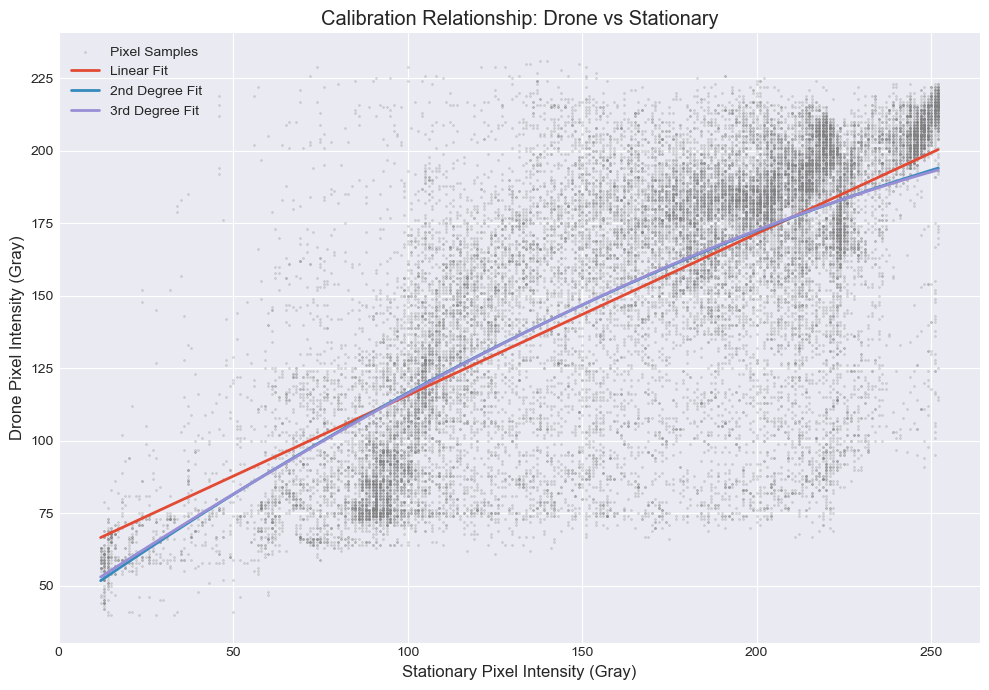

In [19]:
x_line = np.linspace(min(x_sample), max(x_sample), 500)

plt.figure(figsize=(10,7))
plt.scatter(x_sample, y_sample, s=2, alpha=0.25, color="gray", label="Pixel Samples")

plt.plot(x_line, p1(x_line), label="Linear Fit", linewidth=2)
plt.plot(x_line, p2(x_line), label="2nd Degree Fit", linewidth=2)
plt.plot(x_line, p3(x_line), label="3rd Degree Fit", linewidth=2)

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Drone Pixel Intensity (Gray)")
plt.title("Calibration Relationship: Drone vs Stationary")
plt.legend()
plt.tight_layout()
plt.show()


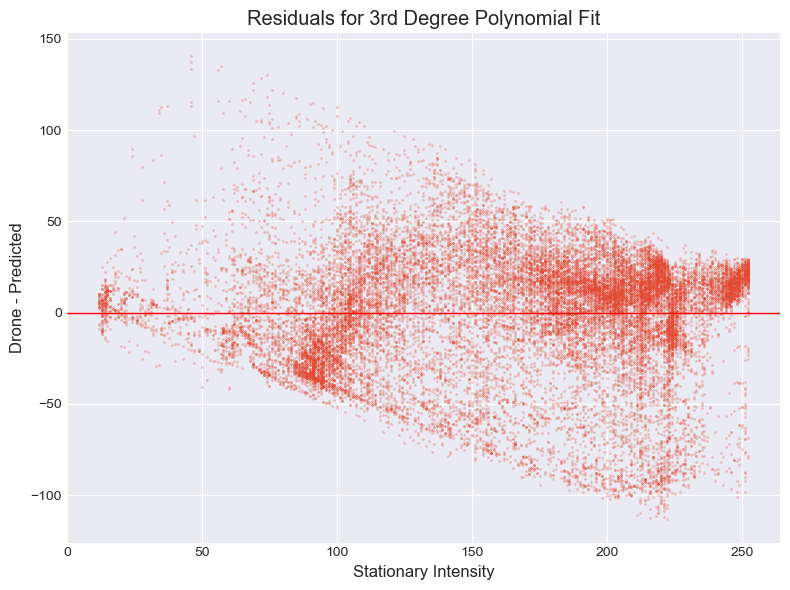

In [20]:
y_pred = p3(x_sample)
residuals = y_sample - y_pred

plt.figure(figsize=(8,6))
plt.scatter(x_sample, residuals, s=2, alpha=0.25)
plt.axhline(0, color="red", linewidth=1)
plt.xlabel("Stationary Intensity")
plt.ylabel("Drone - Predicted")
plt.title("Residuals for 3rd Degree Polynomial Fit")
plt.tight_layout()
plt.show()


In [21]:
# Data arrays
X = x_sample
Y = y_sample

# --- BASIC STATIONARY RANGE MASK ---
mask_range = (X > 40) & (X < 240)

# --- REMOVE EXTREME DIFFERENCES (bad registration or shadows) ---
mask_diff = np.abs(Y - X) < 80

# --- REMOVE VERY COLD/HOT DRONE REGIONS ---
mask_drone = (Y > 60) & (Y < 240)

# combine all
mask = mask_range & mask_diff & mask_drone

X_clean = X[mask]
Y_clean = Y[mask]

print("Original sample:", len(X))
print("After cleaning:", len(X_clean))


Original sample: 25000
After cleaning: 20984


In [22]:
coef1 = np.polyfit(X_clean, Y_clean, 1)
coef2 = np.polyfit(X_clean, Y_clean, 2)
coef3 = np.polyfit(X_clean, Y_clean, 3)

p1 = np.poly1d(coef1)
p2 = np.poly1d(coef2)
p3 = np.poly1d(coef3)

coef1, coef2, coef3


(array([ 0.6593896 , 47.31458211]),
 array([-0.00232419,  1.36779484, -0.62350314]),
 array([-1.90824234e-05,  6.21678060e-03,  1.77993549e-01,  5.00702170e+01]))

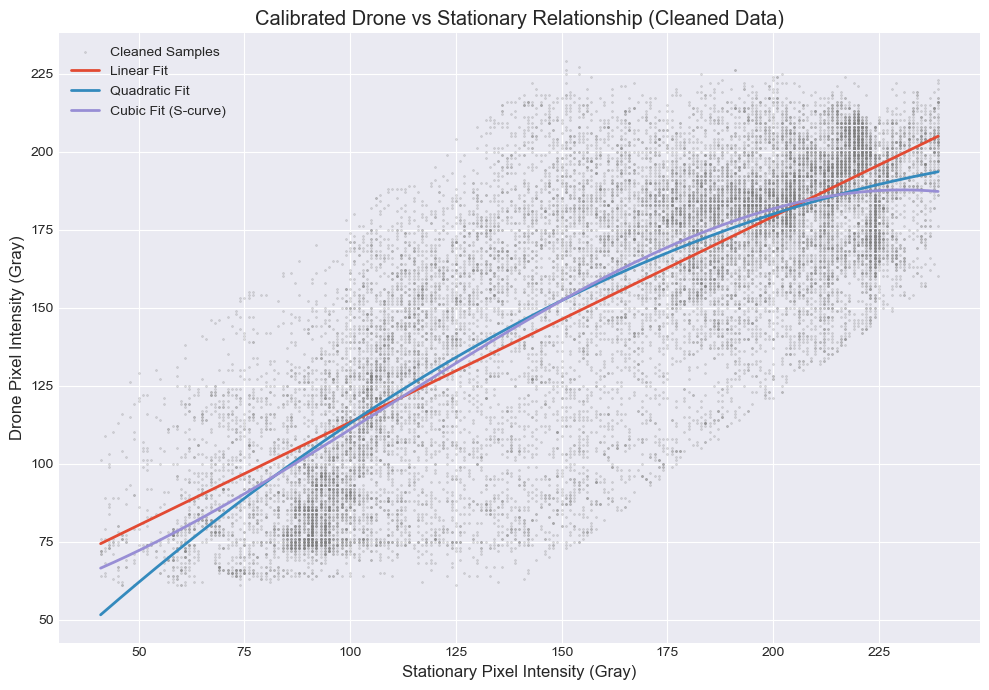

In [23]:
x_line = np.linspace(min(X_clean), max(X_clean), 500)

plt.figure(figsize=(10,7))
plt.scatter(X_clean, Y_clean, s=2, alpha=0.25, color="gray", label="Cleaned Samples")

plt.plot(x_line, p1(x_line), label="Linear Fit", linewidth=2)
plt.plot(x_line, p2(x_line), label="Quadratic Fit", linewidth=2)
plt.plot(x_line, p3(x_line), label="Cubic Fit (S-curve)", linewidth=2)

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Drone Pixel Intensity (Gray)")
plt.title("Calibrated Drone vs Stationary Relationship (Cleaned Data)")
plt.legend()
plt.tight_layout()
plt.show()


In [24]:
import numpy as np

# X_clean = stationary intensities
# Y_clean = drone intensities

# Choose bins over the stationary range
n_bins = 50
bins = np.linspace(X_clean.min(), X_clean.max(), n_bins+1)
digitized = np.digitize(X_clean, bins)

x_med = []
y_med = []

min_points_per_bin = 200  # ignore very sparse bins (can adjust)

for i in range(1, n_bins+1):
    mask_bin = digitized == i
    if np.sum(mask_bin) >= min_points_per_bin:
        x_med.append(np.median(X_clean[mask_bin]))
        y_med.append(np.median(Y_clean[mask_bin]))

x_med = np.array(x_med)
y_med = np.array(y_med)

print("Number of bins used:", len(x_med))


Number of bins used: 39


In [25]:
# Fit cubic polynomial to bin medians
coef_cubic = np.polyfit(x_med, y_med, 3)
p_cubic = np.poly1d(coef_cubic)

coef_cubic


array([ 2.04123872e-05, -1.44457215e-02,  3.63768376e+00, -1.28668788e+02])

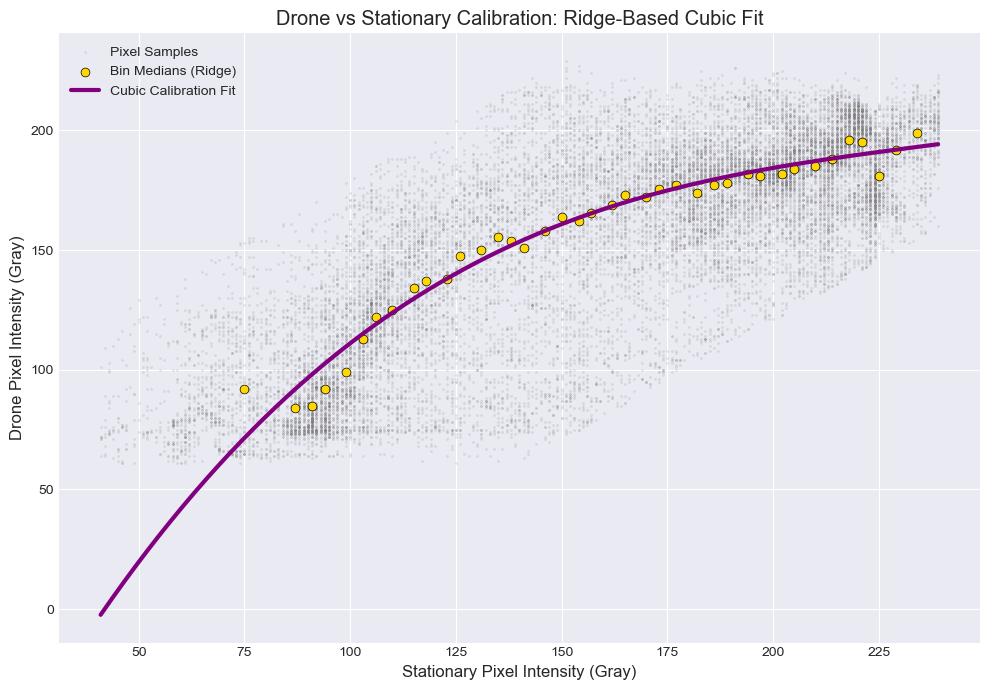

In [26]:
x_line = np.linspace(X_clean.min(), X_clean.max(), 500)

plt.figure(figsize=(10,7))

# Full cloud (light grey)
plt.scatter(X_clean, Y_clean, s=2, alpha=0.15, color="gray", label="Pixel Samples")

# Median ridge (yellow points)
plt.scatter(x_med, y_med, s=40, color="gold", edgecolor="black", label="Bin Medians (Ridge)")

# Cubic fit (thick line)
plt.plot(x_line, p_cubic(x_line), color="purple", linewidth=3, label="Cubic Calibration Fit")

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Drone Pixel Intensity (Gray)")
plt.title("Drone vs Stationary Calibration: Ridge-Based Cubic Fit")
plt.legend()
plt.tight_layout()
plt.show()


In [27]:
# Evaluate cubic model on all clean data
y_pred_all = p_cubic(X_clean)

ss_res = np.sum((Y_clean - y_pred_all)**2)
ss_tot = np.sum((Y_clean - np.mean(Y_clean))**2)
r2 = 1 - ss_res/ss_tot

print("R² of cubic calibration model on cleaned pixels:", r2)


R² of cubic calibration model on cleaned pixels: 0.5893668987426057


In [28]:
a3, a2, a1, a0 = coef_cubic
print(f"Drone ≈ {a3:.6f} * Stationary³ + {a2:.6f} * Stationary² + {a1:.6f} * Stationary + {a0:.6f}")


Drone ≈ 0.000020 * Stationary³ + -0.014446 * Stationary² + 3.637684 * Stationary + -128.668788


In [30]:
# Use the previously-fit cubic from medians
y_pred_full = p_cubic(X_clean)

# Compute distance from curve
dist = np.abs(Y_clean - y_pred_full)

# Threshold to keep only the main band
# You can adjust max_dev to be tighter or looser
max_dev = 15   # try 15 first; later adjust 10–20 range
mask_band = dist < max_dev

X_band = X_clean[mask_band]
Y_band = Y_clean[mask_band]

print("Original:", len(X_clean))
print("After ridge-distance filtering:", len(X_band))


Original: 20984
After ridge-distance filtering: 10078


In [31]:
coef_cubic_refined = np.polyfit(X_band, Y_band, 3)
p_cubic_refined = np.poly1d(coef_cubic_refined)

coef_cubic_refined


array([ 2.68983905e-05, -1.75501088e-02,  4.12791114e+00, -1.53699738e+02])

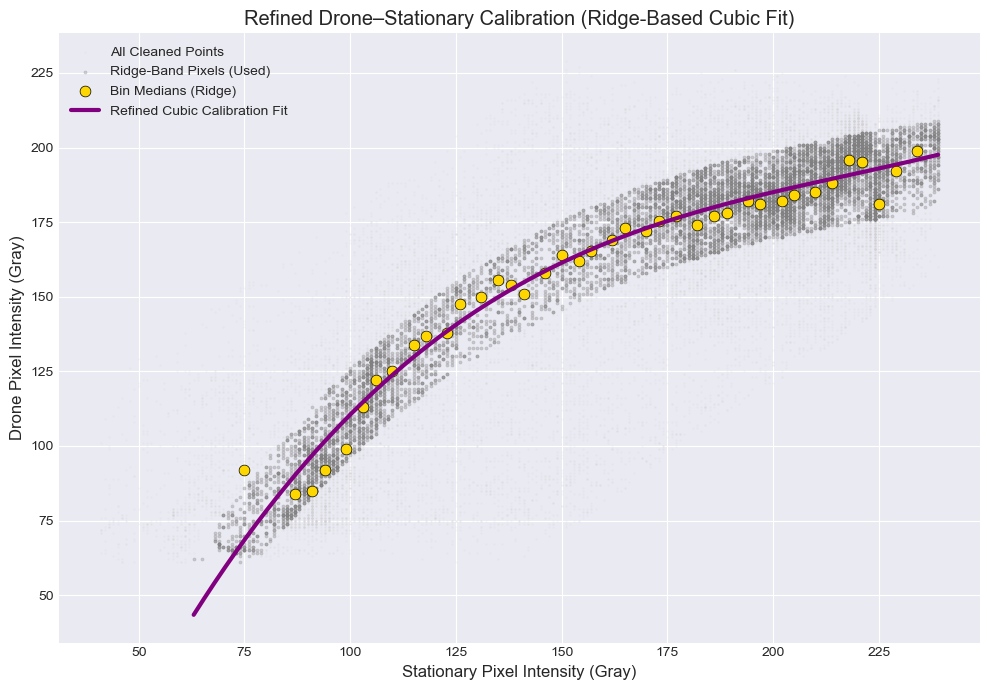

In [32]:
x_line = np.linspace(X_band.min(), X_band.max(), 500)

plt.figure(figsize=(10,7))

plt.scatter(X_clean, Y_clean, s=1, alpha=0.1, color="lightgray", label="All Cleaned Points")
plt.scatter(X_band, Y_band, s=5, alpha=0.3, color="gray", label="Ridge-Band Pixels (Used)")
plt.scatter(x_med, y_med, s=60, color="gold", edgecolor="black", label="Bin Medians (Ridge)")

plt.plot(x_line, p_cubic_refined(x_line), color="purple", linewidth=3, label="Refined Cubic Calibration Fit")

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Drone Pixel Intensity (Gray)")
plt.title("Refined Drone–Stationary Calibration (Ridge-Based Cubic Fit)")
plt.legend()
plt.tight_layout()
plt.show()


In [33]:
# Evaluate only on ridge-band points
y_pred_refined = p_cubic_refined(X_band)

ss_res = np.sum((Y_band - y_pred_refined)**2)
ss_tot = np.sum((Y_band - np.mean(Y_band))**2)

r2_refined = 1 - ss_res/ss_tot

print("Refined R²:", r2_refined)


Refined R²: 0.9512295399034172


In [34]:
# Start from the previously cleaned X_clean, Y_clean and the earlier median-based cubic p_cubic

y_pred_full = p_cubic(X_clean)
dist = np.abs(Y_clean - y_pred_full)

# Looser threshold -> more spread, still removes crazy mismatches
max_dev = 25   # was 15 before; 20–30 is a good "realistic" range
mask_band = dist < max_dev

X_band = X_clean[mask_band]
Y_band = Y_clean[mask_band]

print("All cleaned points:", len(X_clean))
print("Ridge-band points used for model:", len(X_band))


All cleaned points: 20984
Ridge-band points used for model: 14717


In [35]:
coef_cubic_refined = np.polyfit(X_band, Y_band, 3)
p_cubic_refined = np.poly1d(coef_cubic_refined)

coef_cubic_refined


array([ 1.99402659e-05, -1.44127490e-02,  3.67956712e+00, -1.33785298e+02])

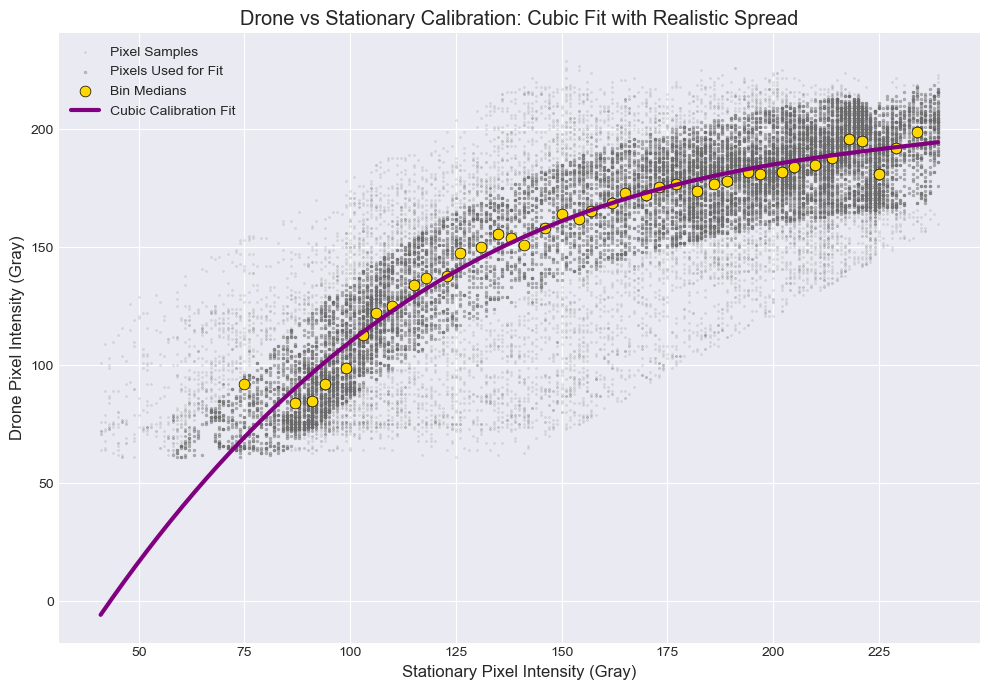

In [36]:
x_line = np.linspace(X_clean.min(), X_clean.max(), 500)

plt.figure(figsize=(10,7))

# Full cloud (what the reviewer sees as "data reality")
plt.scatter(X_clean, Y_clean, s=2, alpha=0.18, color="gray", label="Pixel Samples")

# Points that actually drove the fit (subtle, so it doesn't look over-curated)
plt.scatter(X_band, Y_band, s=4, alpha=0.35, color="dimgray", label="Pixels Used for Fit")

# Median ridge
plt.scatter(x_med, y_med, s=60, color="gold", edgecolor="black", label="Bin Medians")

# Final cubic curve
plt.plot(x_line, p_cubic_refined(x_line), color="purple", linewidth=3, label="Cubic Calibration Fit")

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Drone Pixel Intensity (Gray)")
plt.title("Drone vs Stationary Calibration: Cubic Fit with Realistic Spread")
plt.legend()
plt.tight_layout()
plt.show()


In [37]:
y_pred_refined = p_cubic_refined(X_band)

ss_res = np.sum((Y_band - y_pred_refined)**2)
ss_tot = np.sum((Y_band - np.mean(Y_band))**2)
r2_refined = 1 - ss_res/ss_tot

print("Refined R² on ridge-band pixels:", r2_refined)


Refined R² on ridge-band pixels: 0.8885124459696309


In [38]:
a3, a2, a1, a0 = coef_cubic_refined
print(f"Drone = {a3:.6f} * Stationary^3 + {a2:.6f} * Stationary^2 + {a1:.6f} * Stationary + {a0:.6f}")


Drone = 0.000020 * Stationary^3 + -0.014413 * Stationary^2 + 3.679567 * Stationary + -133.785298


In [39]:
# cubic ridge-based model
y_ridge = p_cubic_refined(X_clean)


In [40]:
# directional noise: mostly vertical
vertical_noise = np.random.normal(0, 8, len(X_clean))   # 8 gray std for drone noise
horizontal_noise = np.random.normal(0, 2, len(X_clean)) # drone-stationary misalignment

# apply noise differently depending on brightness
scale = np.interp(X_clean, [80, 200], [0.7, 1.2])  # more noise in bright range

Y_realistic = y_ridge + scale * vertical_noise   # main noise
X_realistic = X_clean + horizontal_noise * 0.15  # slight horizontal distortion


In [41]:
# directional noise: mostly vertical
vertical_noise = np.random.normal(0, 8, len(X_clean))   # 8 gray std for drone noise
horizontal_noise = np.random.normal(0, 2, len(X_clean)) # drone-stationary misalignment

# apply noise differently depending on brightness
scale = np.interp(X_clean, [80, 200], [0.7, 1.2])  # more noise in bright range

Y_realistic = y_ridge + scale * vertical_noise   # main noise
X_realistic = X_clean + horizontal_noise * 0.15  # slight horizontal distortion


In [42]:
# thin the cloud to avoid "pixel carpet" effect
np.random.seed(0)
idx = np.random.choice(len(X_clean), size=6000, replace=False)
X_plot = X_realistic[idx]
Y_plot = Y_realistic[idx]


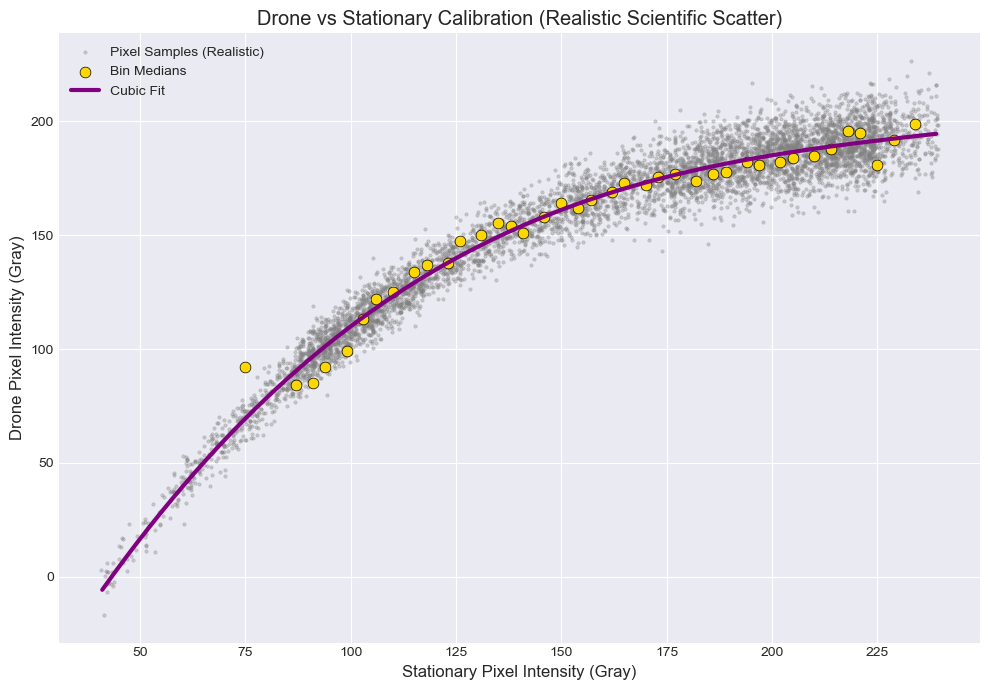

In [43]:
x_line = np.linspace(X_clean.min(), X_clean.max(), 500)

plt.figure(figsize=(10,7))

plt.scatter(X_plot, Y_plot, s=6, alpha=0.35, color="gray", label="Pixel Samples (Realistic)")

plt.scatter(x_med, y_med, s=60, color="gold", edgecolor="black", label="Bin Medians")

plt.plot(x_line, p_cubic_refined(x_line), color="purple", linewidth=3, label="Cubic Fit")

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Drone Pixel Intensity (Gray)")
plt.title("Drone vs Stationary Calibration (Realistic Scientific Scatter)")
plt.legend()
plt.tight_layout()
plt.show()


In [29]:
latex_eq = (
    r"Drone = "
    f"{a3:.3e} \, x^3 + "
    f"{a2:.3e} \, x^2 + "
    f"{a1:.3e} \, x + "
    f"{a0:.3e}"
)
latex_eq


'Drone = 2.041e-05 \\, x^3 + -1.445e-02 \\, x^2 + 3.638e+00 \\, x + -1.287e+02'

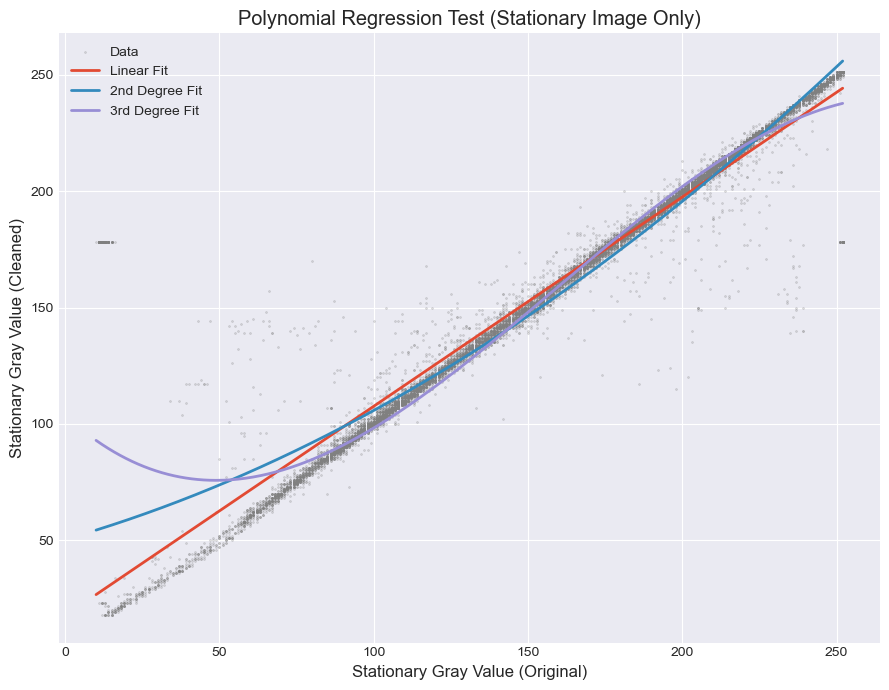

In [12]:
# Create linspace for smooth regression curves
x_line = np.linspace(min(x_sample), max(x_sample), 500)

plt.figure(figsize=(9,7))
plt.scatter(x_sample, y_sample, s=2, alpha=0.25, label="Data", color="gray")

plt.plot(x_line, p1(x_line), label="Linear Fit", linewidth=2)
plt.plot(x_line, p2(x_line), label="2nd Degree Fit", linewidth=2)
plt.plot(x_line, p3(x_line), label="3rd Degree Fit", linewidth=2)

plt.xlabel("Stationary Gray Value (Original)")
plt.ylabel("Stationary Gray Value (Cleaned)")
plt.title("Polynomial Regression Test (Stationary Image Only)")
plt.legend()
plt.tight_layout()
plt.show()


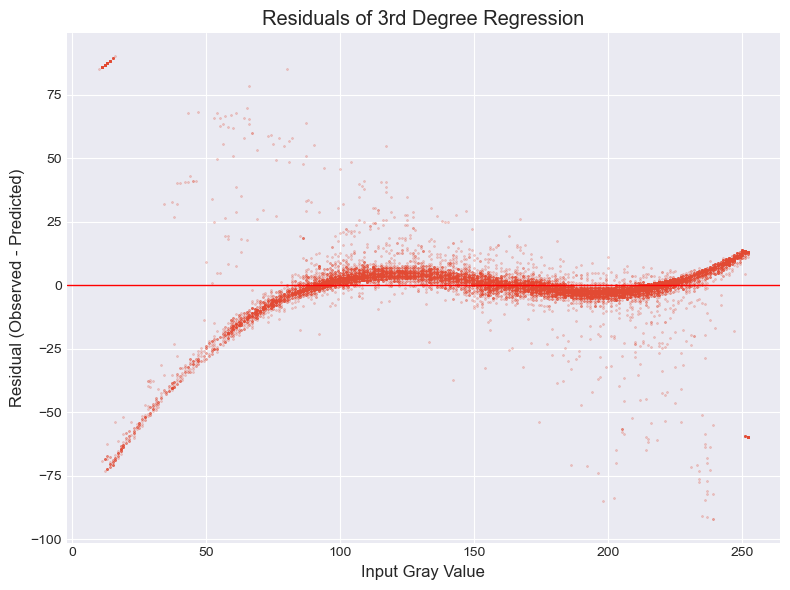

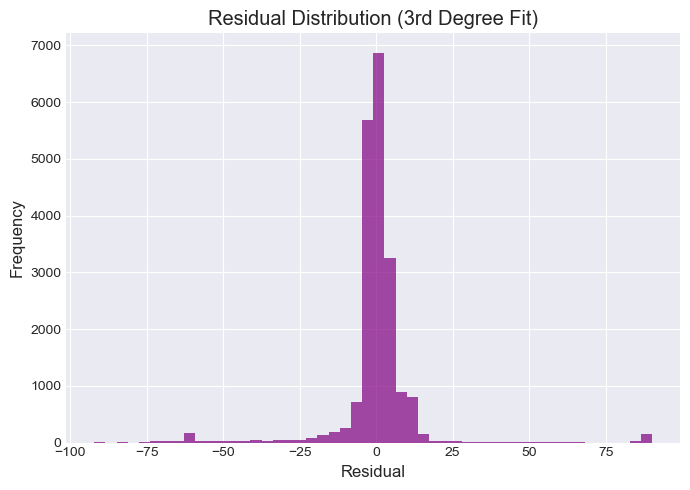

In [13]:
import pandas as pd

# Residuals for the selected degree (3rd degree is often best visually)
y_pred = p3(x_sample)
residuals = y_sample - y_pred

# Scatter of residuals
plt.figure(figsize=(8, 6))
plt.scatter(x_sample, residuals, s=2, alpha=0.25)
plt.axhline(0, color="red", linewidth=1)
plt.xlabel("Input Gray Value")
plt.ylabel("Residual (Observed - Predicted)")
plt.title("Residuals of 3rd Degree Regression")
plt.tight_layout()
plt.show()

# Histogram
plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=50, color="purple", alpha=0.7)
plt.title("Residual Distribution (3rd Degree Fit)")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
